# Modelos de Regresión Lineal

## Objetivos:

Aplicar técnicas de regresión lineal para analizar relaciones entre variables, utilizando Python como herramienta de apoyo.

*Nota: Este laboratorio está diseñado para desarrollar razonamiento estadístico. Evita el uso de herramientas de IA para responder las preguntas a menos que esto sea explícitamente sugerido* 🤖. *En su lugar, enfócate en aplicar los conceptos revisados.*

## Actividad 1

Trabajas como analista de datos en el equipo de marketing digital de una tienda online del Reino Unido especializada en productos electrónicos y artículos de lujo. En el contexto de esta empresa, las ventas dependen de la cantidad de visitas que recibe el sitio web. El gerente de ventas está evaluando si conviene aumentar la inversión en campañas publicitarias para atraer más usuarios. Para ello, te entrega una base de datos con el número de visitas diarias al sitio y las ventas totales por día (en libras esterlinas). El gerente te solicita que analices la relación entre ambas variables y proporciones evidencia, basada en los datos disponibles, que respalde esta dependencia.

Para esto puedes descargar la base de datos **<a href="https://docs.google.com/spreadsheets/d/1bmYIXcn3SPyrJHi6IWzvj2t_fSkn6pyj/export?format=xlsx">aquí</a>** y responder las siguientes preguntas:

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress



1. Muestra las tres primeras filas de la base de datos.

In [4]:
df1 = pd.read_excel('Base6_1.xlsx')
df1.head()

,fecha,visitas_diarias,ventas_diarias
0,2010-12-01,121,46376.49
1,2010-12-02,137,47316.53
2,2010-12-03,57,23921.71
3,2010-12-05,87,31771.60
4,2010-12-06,94,31215.64


2. Calcula la covarianza y el coeficiente de correlación lineal entre las visitas diarias y las ventas diarias utilizando los datos disponibles. ¿Qué indican estos resultados en cuanto a la relación entre las visitas al sitio web y las ventas?

In [15]:
# Covarianza 
covarianza = round(df1["visitas_diarias"].cov(df1["ventas_diarias"]),2)

# Coeficiente de correlación 
correlacion = round(df1["visitas_diarias"].corr(df1["ventas_diarias"]),4)

print("Covarianza:", covarianza)
print("Coeficiente de correlación:", correlacion)
print()
print(
    "Interpretación: La covarianza es positiva (265.561,77), indicando que las visitas y las ventas tienden a variar\n"
    "en la misma dirección. El coeficiente de correlación es 0,5998, lo que refleja una relación lineal positiva moderada.\n"
    "Esto significa que, al aumentar las visitas al sitio web, las ventas tienden a aumentar,\n"
    "aunque no necesariamente de forma proporcional."
)

Covarianza: 265561.77
Coeficiente de correlación: 0.5998

Interpretación: La covarianza es positiva (265.561,77), indicando que las visitas y las ventas tienden a variar
en la misma dirección. El coeficiente de correlación es 0,5998, lo que refleja una relación lineal positiva moderada.
Esto significa que, al aumentar las visitas al sitio web, las ventas tienden a aumentar,
aunque no necesariamente de forma proporcional.


3. Encuentra el modelo de regresión lineal asociado a los datos e interpreta la pendiente.

In [17]:
from scipy.stats import linregress

regresion = linregress(df1["visitas_diarias"], df1["ventas_diarias"])

print(f"Modelo de regresión: Ventas = {regresion.intercept:.2f} + {regresion.slope:.2f} * visitas_diarias")
print(f"Pendiente: {regresion.slope:.2f}")


Modelo de regresión: Ventas = 2971.69 + 431.86 * visitas_diarias
Pendiente: 431.86


4. Genera un gráfico de dispersión que relacione las visitas diarias con las ventas diarias. Incorpora la línea de tendencia (regresión lineal) e incluye el modelo lineal en el gráfico. Luego, describe lo que observas.

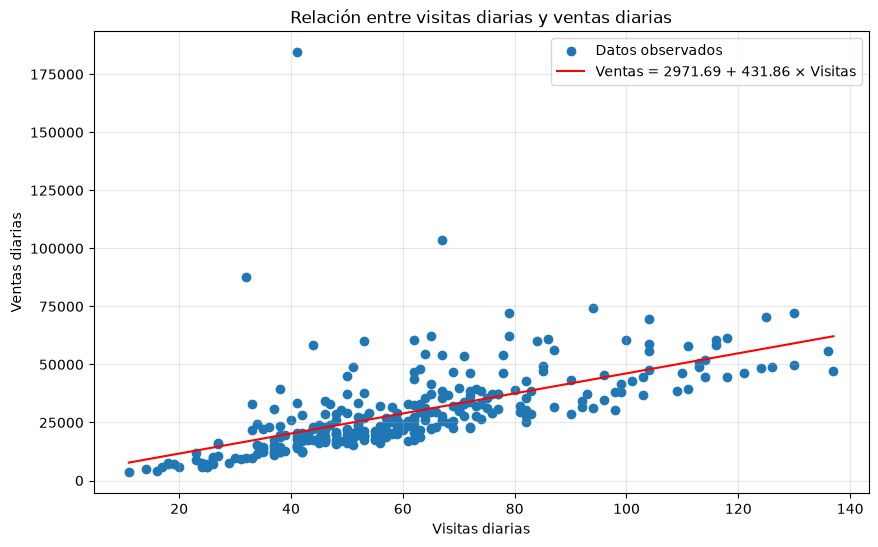

In [19]:

# Variables
x = df1["visitas_diarias"]
y = df1["ventas_diarias"]

# Regresión lineal
regresion = linregress(x, y)
pendiente = regresion.slope
intercepto = regresion.intercept

# Línea de tendencia
x_linea = np.linspace(x.min(), x.max(), 100)
y_linea = pendiente * x_linea + intercepto

# Gráfico
plt.figure(figsize=(10, 6))
plt.scatter(x, y, label="Datos observados")
plt.plot(
    x_linea, y_linea,
    color="red",
    label=f"Ventas = {intercepto:.2f} + {pendiente:.2f} × Visitas"
)

plt.title("Relación entre visitas diarias y ventas diarias")
plt.xlabel("Visitas diarias")
plt.ylabel("Ventas diarias")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

El gráfico de dispersión permite observar una tendencia positiva entre las visitas diarias y las ventas. La línea de regresión muestra que, en general, las ventas tienden a aumentar cuando se incrementan las visitas al sitio web. Sin embargo, los puntos presentan cierta dispersión, lo que indica que existen otros factores que también pueden influir en las ventas.

5. Al observar la distancia de los puntos con la línea de tendencia ¿qué observas sobre la dispersión de los puntos respecto a la línea de tendencia?

6. Usando el modelo de regresión lineal determinado, estima las ventas que se generarían si el sitio recibiera 350 visitas en un día.

In [20]:
visitas = 350

ventas_estimadas = regresion.intercept + regresion.slope * visitas

print(f"Ventas estimadas para 350 visitas: {ventas_estimadas:.2f}")

Ventas estimadas para 350 visitas: 154124.30


7. Calcula el coeficiente de determinación $R^{2}$ e interpreta su valor.

In [21]:
c_determinacion = regresion.rvalue ** 2

print(f"Coeficiente de determinación R²: {c_determinacion:.4f}")
print(f"Porcentaje explicado por el modelo: {c_determinacion * 100:.2f}%")

Coeficiente de determinación R²: 0.3597
Porcentaje explicado por el modelo: 35.97%


## Actividad 2

Un grupo de docentes tiene como objetivo analizar si existe una relación entre tiempo de estudio semanal (en horas) y el rendimiento académico de los estudiantes en la nota obtenida en una evaluación (en puntos). Para ello, se recopiló información de 200 estudiantes pertenecientes a carreras del área informática de un instituto profesional.

Descarga la base de datos **<a href="https://drive.google.com/uc?export=download&id=1ATKPCSFq2xcGzEUme2jEHKsSYcaf75LO
">aquí</a>** y responde las siguientes preguntas:

1. Explora la base de datos y muestra las primeras 5 filas del DataFrame.

2. ¿Cuál es la variable dependiente y cuál la independiente en el análisis que los docentes planean desarrollar?

3. Calcula la covarianza y el coeficiente de correlación lineal de Pearson. Considerando estos valores, comenta cómo es la relación entre las variables.

4. Determina el modelo de regresión lineal correspondiente a los datos e interpreta el valor de la pendiente.

5. Genera un gráfico de dispersión que represente la relación entre las variables. Incorpora la línea de tendencia (regresión lineal) e incluye el modelo lineal en el gráfico. Luego, comenta lo observado.

6. Observando el gráfico, estime la nota de un estudiante que dedica 20 horas semanales al estudio y de otro que estudia solo 3 horas. Compare posteriormente estos valores con las estimaciones generadas por el modelo lineal determinado.

7. ¿Es útil este modelo para predecir? Justifica utilizando el coeficiente de determinación ($R^{2}$).

## Actividad 3

Una empresa de servicios técnicos desea analizar la relación entre el número de trabajadores asignados a un proyecto y el tiempo total (en horas) que toma completarlo. Para ello, ha recopilado información de 150 proyectos técnicos de mediana envergadura, como instalaciones de redes, montajes de hardware y configuraciones masivas.

Descargar la base de datos **<a href="https://docs.google.com/spreadsheets/d/1HQgGNDwDGoDqCU5YECgwNh724iLgUORz/export?format=xlsx">aquí</a>** y responde las siguientes preguntas:

1. Muestra las primeras cinco filas de la base de datos.

2. ¿Qué representa cada fila de la base de datos?

3. Al analizar la relación entre la cantidad de trabajadores y el tiempo total del proyecto, ¿cuál es la variable dependiente? ¿Y la independiente?

4. Calcula la covarianza y el coeficiente de correlación lineal de Pearson entre las variables e interpreta los resultados.

5. Determina el modelo de regresión lineal y luego interpreta el valor de la pendiente.

6. Genera un gráfico de dispersión que represente la relación entre las variables. Incorpora la línea de tendencia (regresión lineal) e incluye el modelo lineal en el gráfico. Comenta lo observado.

7. Utiliza el modelo para estimar la duración de un proyecto que cuente con:
* 10 trabajadores.
* 15 trabajadores.
* 18 trabajadores.

8. ¿Qué porcentaje de la variabilidad en el tiempo total de ejecución de los proyectos se explica por la cantidad de trabajadores asignados? Justifique su respuesta.

## Actividad 4

Una empresa de tecnología implementó un programa de formación continua para sus trabajadores. El objetivo es analizar si existe una relación entre el tiempo de formación recibido (en horas) y el puntaje obtenido en la evaluación de desempeño en una prueba interna (en puntos). El análisis se realizó por separado en dos áreas: Soporte Técnico y Desarrollo Web, registrando en cada caso las horas de formación y el puntaje obtenido por cada trabajador.

Tu tarea consiste en analizar estas relaciones y determinar en qué área la formación tiene un mayor impacto sobre el desempeño.

Puedes descargar la base de datos **<a href="https://drive.google.com/uc?export=download&id=1hcrtBDxzmLDxjFWzKvvS-4YPgGDT4lfR
">aquí</a>.**

1. Carga la base de datos y muestra sus primeras 6 filas.

2. Considerando que debes encontrar dos modelos de regresión lineal, ¿qué variables intervienen en cada uno de ellos y cuál corresponde a la variable dependiente en cada caso?

3. Determina el modelo de regresión lineal para cada departamento e interpreta el valor de la pendiente de cada uno.

4. Elabora dos gráficos de dispersión: uno que muestre la relación entre el tiempo de formación y el puntaje en el área de Desarrollo Web, y otro que refleje la misma relación en el área de Soporte Técnico. Posteriormente, describe las observaciones obtenidas.

5. ¿En cuál de las dos áreas (Soporte Técnico o Desarrollo Web) la correlación entre el tiempo de formación y el puntaje es más fuerte? Justifica realizando el cálculo apropiado.

6. ¿En cuál de las dos áreas el modelo de regresión describe mejor la relación entre el tiempo de formación y el puntaje? Justifica tu respuesta.